# A tour of `chladni.helmholtz`

The layer above `geometry`: exact solutions of the Helmholtz equation, evaluated as the
columns of a matrix, which is what the Method of Particular Solutions searches over.

The spectral parameter here is the **wavenumber** `k`, in `laplacian(u) + k**2*u = 0`.
`lam = k**2` is the eigenvalue and belongs one layer up, converted at a single seam.

Every quantitative claim below is asserted inline, so an API change that alters a number
fails the test suite rather than printing something wrong to a reader.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import chladni.plotting as P
from chladni.geometry import Polygon, spiral
from chladni.helmholtz import (
    Basis, CornerModes, FourierBessel, Fundamental, PlaneWave, PrecisionWarning,
)
from chladni.helmholtz._bessel import log_j

plt.rcParams["figure.dpi"] = 110
L_SHAPE = np.array([0, 2, 2 + 1j, 1 + 1j, 1 + 2j, 2j], dtype=complex)
K = 7.3

## 1. The problem this layer exists to solve

At a sharp corner the Fourier-Bessel order runs into the hundreds while `k*r` stays small,
and `scipy.special.jv` does not degrade there -- it holds thirteen digits and then flushes
to exactly `0.0`. A column of zeros is not a small column; it is no column at all.

Values come back factored instead, `J = S * exp(sigma)`, so the whole range is representable
and every entry keeps its full *relative* accuracy.

In [2]:
from scipy.special import jv

nu, x = 400.0, 20.0
s = log_j(nu, x)
print(f"scipy.special.jv({nu:.0f}, {x:.0f}) = {jv(nu, x)!r}")
print(f"log_j:  S = {s.S:.6f},  sigma = {s.sigma:.3f}"
      f"   ->  J = {s.S:.4f} x 10^{s.sigma / np.log(10):.1f}")

assert jv(nu, x) == 0.0                 # scipy has nothing to say here
assert abs(s.S) <= 1.0                  # Watson's bound, in every branch
assert np.isfinite(s.sigma)

scipy.special.jv(400, 20) = np.float64(0.0)
log_j:  S = 0.779226,  sigma = -1079.467   ->  J = 0.7792 x 10^-468.8


In [3]:
# Where the cliff is, bisected against scipy itself.
edges = []
for order in (100, 200, 300, 400, 500, 700):
    lo, hi = 1e-6, 1e4
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if jv(order, mid) == 0.0 else (lo, mid)
    edges.append((order, hi))
print("order   x where jv first returns a nonzero value")
for order, e in edges:
    print(f"{order:5d}   {e:8.3f}")

assert edges[0][1] < 0.2 and edges[-1][1] > 100

order   x where jv first returns a nonzero value
  100      0.096
  200      5.319
  300     23.978
  400     51.742
  500     92.062
  700    194.082


## 2. Corner modes

`geometry` stops at the interior angle and the boundary-condition pair, and never computes
`nu = pi/theta`. That happens here, and the quantization decouples: the condition on the
outgoing ray picks sine against cosine, the one on the incoming ray picks a half-integer
offset. Two booleans, one code path -- so a mixed-BC (Zaremba) corner costs nothing.

In [4]:
theta = 1.4 * np.pi
rows = []
for bc_out, bc_in, label in [(0.0, 0.0, "dir / dir"), (1.0, 1.0, "neu / neu"),
                             (0.0, 1.0, "dir / neu"), (1.0, 0.0, "neu / dir")]:
    m = CornerModes.from_wedge(theta, bc_out, bc_in)
    rows.append((label, m.kind, m.offset, m.leading_exponent))
    print(f"{label}   angular={m.kind}   offset={m.offset}   leading mu={m.leading_exponent:.4f}")

# the mixed families carry exactly half the leading exponent of the unmixed ones
assert rows[2][3] == rows[3][3]
assert abs(rows[2][3] - 0.5 * rows[0][3]) < 1e-14

# a FLAT boundary-condition junction is the classic square-root singularity, and it is
# invisible to any test on the angle alone
flat = CornerModes.from_wedge(np.pi, 0.0, 1.0)
print(f"\nflat dir/neu junction: leading mu = {flat.leading_exponent}")
assert flat.leading_exponent == 0.5

dir / dir   angular=sin   offset=0.0   leading mu=0.7143
neu / neu   angular=cos   offset=0.0   leading mu=0.0000
dir / neu   angular=sin   offset=0.5   leading mu=0.3571
neu / dir   angular=cos   offset=0.5   leading mu=0.3571

flat dir/neu junction: leading mu = 0.5


## 3. A corner family, and the ray it vanishes on

The angle is lifted with the branch cut as its anchor, not with a modulo. That is what makes
the boundary condition on the outgoing ray hold *structurally* -- `sin(mu*0)`, exactly zero,
not zero to roundoff.

In [5]:
poly = Polygon(L_SHAPE)
reentrant = [c for c in poly.corners if c.is_reentrant][0]
fam = FourierBessel.at_corner(reentrant, n=6, domain=poly)
print(fam)
print(f"nu = {fam.modes.nu:.6f}   orders = {np.round(fam.orders, 3)}")

r = np.linspace(0.01, 0.9, 40)
on_ray = fam.values(K, reentrant.z + r * reentrant.t_out)
print(f"\nmax |u| on the outgoing ray: {np.abs(on_ray).max()!r}")
assert np.all(on_ray == 0.0)                    # exactly, not approximately
assert abs(fam.modes.nu - 2 / 3) < 1e-14

FourierBessel(origin=1+1j, nu=0.666667, kind='sin', n_cols=6)
nu = 0.666667   orders = [0.667 1.333 2.    2.667 3.333 4.   ]

max |u| on the outgoing ray: np.float64(0.0)


In [6]:
# ... and every column really does solve the Helmholtz equation.
# Points held clear of the boundary: the finite-difference stencil must not step across
# the branch cut, which leaves Omega at the corner but is only a stencil-width away from
# the interior right next to it. That is the cut behaving correctly, not the code failing.
pts = poly.interior_pts(600, rng=np.random.default_rng(0))
pts = pts[poly.boundary_distance(pts) > 0.05][:200]
h = 1e-3
u = lambda z: fam.values(K, z)
lap = np.zeros_like(u(pts))
for step in (h, 1j * h):
    lap += (-u(pts + 2 * step) + 16 * u(pts + step) - 30 * u(pts)
            + 16 * u(pts - step) - u(pts - 2 * step)) / (12 * h**2)
res = np.abs(lap + K**2 * u(pts)).max() / (K**2 * np.abs(u(pts)).max())
print(f"relative Helmholtz residual (4th-order FD, h=1e-3): {res:.2e}")
assert res < 5e-9      # the floor here is the differencing, not the code

relative Helmholtz residual (4th-order FD, h=1e-3): 4.96e-09


## 4. Seeing the branch cut

The fastest way to know a cut is in the wrong place is to look at it. `phi` is continuous on
the domain and jumps by `2*pi` across the cut, which must lie entirely outside `Omega`.

largest step in phi between neighbouring interior cells: 0.038


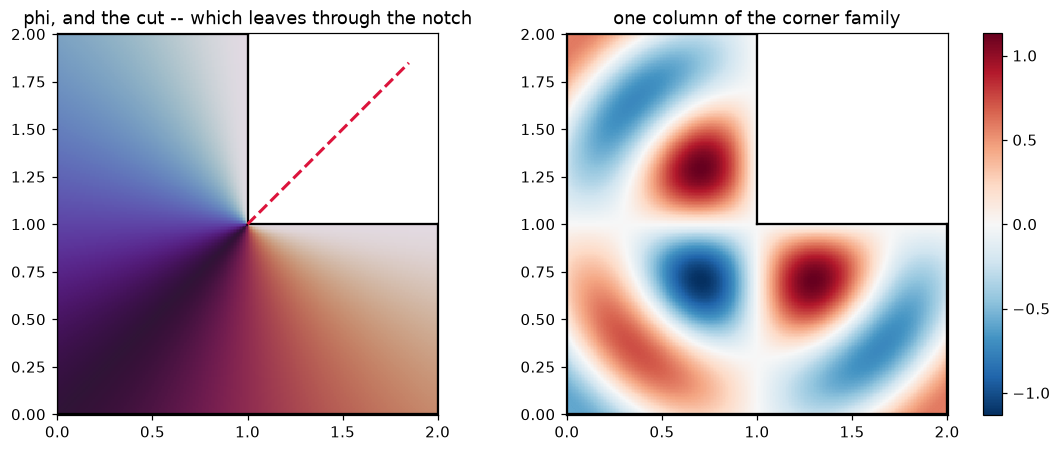

In [7]:
X, Y, mask = P.field_grid(poly, 260)
Z = X + 1j * Y
phi = fam.at(Z.ravel()).phi.reshape(X.shape)

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4), constrained_layout=True)
ax[0].pcolormesh(X, Y, np.where(mask, phi, np.nan), cmap="twilight", shading="auto")
P.plot_domain(poly, ax=ax[0], fill=False)
cut = reentrant.branch_path(1.2)
ax[0].plot(cut.real, cut.imag, "--", color="crimson", lw=2)
ax[0].set_title("phi, and the cut -- which leaves through the notch")
ax[0].set_aspect("equal")

col = fam.values(K, Z.ravel())[:, 2].reshape(X.shape)
m = ax[1].pcolormesh(X, Y, np.where(mask, col, np.nan), cmap="RdBu_r", shading="auto")
P.plot_domain(poly, ax=ax[1], fill=False)
ax[1].set_title("one column of the corner family")
ax[1].set_aspect("equal")
fig.colorbar(m, ax=ax[1])

# phi is continuous on Omega: no 2*pi jump anywhere inside. Sampled away from the corner
# itself, where the angle legitimately sweeps 3*pi/2 within a couple of grid cells.
far = mask & (np.abs(Z - reentrant.z) > 0.2)
step = np.abs(np.diff(np.where(far, phi, np.nan), axis=0))
print(f"largest step in phi between neighbouring interior cells: {np.nanmax(step):.3f}")
assert np.nanmax(step) < 1.0

When no straight ray escapes -- a spiral's inner corners are surrounded -- `geometry`
wall-follows and hands back a polyline, and the family puts its branch there.

12 of 24 spiral corners need a polyline cut
1 jumps on the circle, all within 1.75e-06 of the cut (one angular sample is 7.85e-04)


Text(0.5, 1.0, 'a wall-following cut, and the jumps it carries')

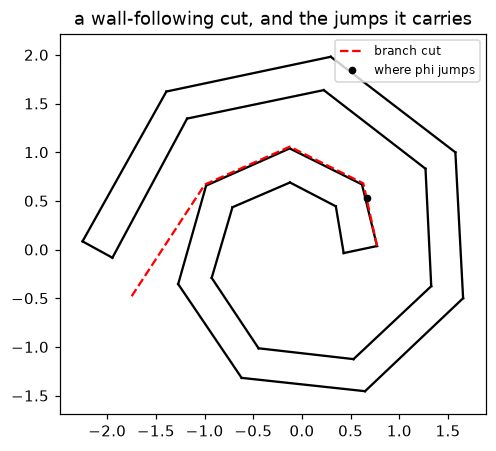

In [8]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sp = spiral()
walled = [c for c in sp.corners if c.branch_vertices]
print(f"{len(walled)} of {len(sp.corners)} spiral corners need a polyline cut")

c = walled[0]
sfam = FourierBessel.at_corner(c, n=1, domain=sp)
rho, n = 0.5, 4000
a = np.linspace(0, 2 * np.pi, n, endpoint=False)
z = c.z + rho * np.exp(1j * a)
jumps = np.nonzero(np.abs(np.diff(sfam.at(z).phi)) > np.pi)[0]

# Long, for the distance test below: the cut has to be followed all the way out.
path = c.branch_path(50 * sp.diameter)
mid = 0.5 * (z[jumps] + z[jumps + 1])
p0, p1 = path[:-1], path[1:]
d = p1 - p0
t = np.clip(((mid[:, None] - p0).real * d.real
             + (mid[:, None] - p0).imag * d.imag) / np.abs(d) ** 2, 0, 1)
off = np.abs(mid[:, None] - (p0 + t * d)).min(axis=1).max()
print(f"{len(jumps)} jumps on the circle, all within {off:.2e} of the cut "
      f"(one angular sample is {rho * 2 * np.pi / n:.2e})")
assert off < 2 * rho * 2 * np.pi / n

# Short, for the picture: the cut runs to infinity, and drawing it that way just shrinks
# the spiral to a dot in the corner of the axes.
fig, ax = plt.subplots(figsize=(5, 5))
P.plot_domain(sp, ax=ax, fill=False)
drawn = c.branch_path(0.35 * sp.diameter)
ax.plot(drawn.real, drawn.imag, "r--", lw=1.5, label="branch cut")
ax.plot(mid.real, mid.imag, "ko", ms=4, label="where phi jumps")
lo, hi = sp.bbox
pad = 0.06 * max(hi.real - lo.real, hi.imag - lo.imag)
ax.set_xlim(lo.real - pad, hi.real + pad)
ax.set_ylim(lo.imag - pad, hi.imag + pad)
ax.set_aspect("equal"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("a wall-following cut, and the jumps it carries")

## 5. Scaling

Raw Fourier-Bessel columns at a sharp corner span hundreds of orders of magnitude. Each one
is divided by an analytic per-column scale that depends on `(column, k)` and never on the
evaluation points -- so a downstream unit-norm rescale composes by *adding* log scales.

orders mu from 8.0 to 320.0
log-scale spans 1013 nats = 440 decades

scaled column maxima: [0.984, 1.157]


Text(0.5, 1.0, 'a 500-decade range, made into an O(1) one')

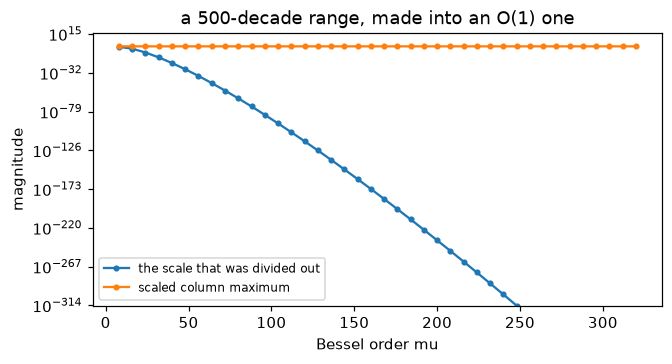

In [9]:
sharp = CornerModes.from_wedge(np.pi / 8, 0.0, 0.0)
f8 = FourierBessel(0j, 1 + 0j, sharp, sharp.degrees(40), radius=1.0)
sig = f8.log_scale(10.0)
print(f"orders mu from {f8.orders.min():.1f} to {f8.orders.max():.1f}")
print(f"log-scale spans {sig.max() - sig.min():.0f} nats "
      f"= {(sig.max() - sig.min()) / np.log(10):.0f} decades")
assert sig.max() - sig.min() > 500
assert np.exp(sig.min()) == 0.0        # the sharpest column is not representable unscaled

rr = np.linspace(1e-8, 1.0, 4000)
s = log_j(f8.orders[None, :], 10.0 * rr[:, None])
scaled_max = np.abs(s.S * np.exp(s.sigma - sig[None, :])).max(axis=0)
print(f"\nscaled column maxima: [{scaled_max.min():.3f}, {scaled_max.max():.3f}]")
assert 0.75 < scaled_max.min() and scaled_max.max() < 1.25

fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
ax.semilogy(f8.orders, np.exp(sig), ".-", label="the scale that was divided out")
ax.semilogy(f8.orders, scaled_max, ".-", label="scaled column maximum")
ax.set_xlabel("Bessel order mu"); ax.set_ylabel("magnitude"); ax.legend(fontsize=8)
ax.set_title("a 500-decade range, made into an O(1) one")

## 6. The other families

Fundamental solutions sit at source points **outside** `Omega` -- an interior pole is not a
particular solution there, and it makes the tension *better* rather than worse, which is why
it raises rather than being filtered. Lightning clustering places them root-exponentially at
a corner.

Fundamental(n_sources=240, order=1, n_cols=240) 
 Fundamental(n_sources=14, order=1, n_cols=14)
innermost lightning pole sits 1.04e-05 from the corner


Text(0.5, 1.0, 'source placement')

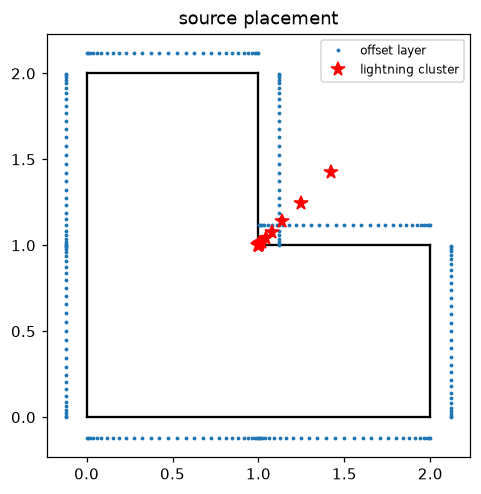

In [10]:
q = poly.bdry_quad(240)
layer = Fundamental.offset(q, 0.12, domain=poly)
bolt = Fundamental.lightning(reentrant, 14, L=0.6)
print(layer, "\n", bolt)
print(f"innermost lightning pole sits {np.abs(bolt.origins - reentrant.z).min():.2e} "
      f"from the corner")
assert not poly.contains(layer.origins).any()
assert not poly.contains(bolt.origins).any()

fig, ax = plt.subplots(figsize=(5, 5))
P.plot_domain(poly, ax=ax, fill=False)
ax.plot(layer.origins.real, layer.origins.imag, ".", ms=3, label="offset layer")
ax.plot(bolt.origins.real, bolt.origins.imag, "r*", ms=9, label="lightning cluster")
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("source placement")

In [11]:
# Plane waves need no scaling at all, and warn when asked for more than are independent.
pw = PlaneWave.uniform(12, radius=poly.diameter / 2)
assert np.array_equal(pw.log_scale(K), np.zeros(len(pw)))
print(f"at k*R = {K * poly.diameter / 2:.1f}, about "
      f"{PlaneWave.n_useful(K * poly.diameter / 2):.0f} directions are independent")

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", PrecisionWarning)
    PlaneWave.uniform(200, radius=poly.diameter / 2).log_scale(K)
print("\nwarning:", str(caught[0].message)[:110], "...")
assert caught and issubclass(caught[0].category, PrecisionWarning)

at k*R = 10.3, about 34 directions are independent



## 7. Composing a basis, and the boundary matrix

`a + b + c` is one flat `Basis`. Bind it to a boundary quadrature once, and every `k` after
that is one evaluation -- the `Sampling` *is* the cache, so there is no eviction policy and
no lock, only an immutable object the solver holds.

In [12]:
fb = [FourierBessel.at_corner(c, n=10, domain=poly) for c in poly.corners]
basis = Basis(fb) + Fundamental.offset(q, 0.12, domain=poly)
print(basis.__class__.__name__, f"with {len(basis.families)} families "
      f"and {len(basis)} columns")

sampling = basis.at(q)              # k-independent, built once
A = sampling.trace(K)               # (1-bc)*u + bc*du_dn, assembled here
print(f"boundary matrix {A.shape}, max |A| = {np.abs(A).max():.3f}")
print(f"worst per-column accuracy bound: {sampling.accuracy(K).max():.2e}")

assert A.shape == (len(q), len(basis))
assert np.isfinite(A).all() and np.abs(A).max() < 10
assert np.array_equal(sampling.trace(K), A)       # reusable, and never mutated

Basis with 7 families and 300 columns
boundary matrix (240, 300), max |A| = 2.390
worst per-column accuracy bound: 2.11e-09


In [13]:
# `cols` is honoured exactly as given -- shuffled, reversed, repeated.
want = np.array([len(basis) - 1, 0, 7, 7])
assert np.array_equal(sampling.values(K, cols=want), sampling.values(K)[:, want])

# and a family with no requested column is never evaluated at all
import time

t0 = time.perf_counter(); sampling.values(K); t_all = time.perf_counter() - t0
own = np.arange(len(fb[0]))
t0 = time.perf_counter(); sampling.values(K, cols=own); t_one = time.perf_counter() - t0
print(f"all {len(basis)} columns: {t_all*1e3:.1f} ms      "
      f"one corner's {len(own)}: {t_one*1e3:.1f} ms")
assert t_one < t_all

all 300 columns: 8.6 ms      one corner's 10: 0.8 ms


## What is not here

Choosing a *good* basis -- how many degrees at which corner, how sources are budgeted,
refinement against a measured residual -- is deliberately deferred. Every family above is
constructible from its own parameters without routing through geometry, which is exactly what
that planning layer will need from this one.

`docs/design/particular_solutions.md` carries the API spec, the measurements behind each
decision, and an "As built" section recording where the code went past the spec and why.